# Project: Abuja Apartment Rent Predictor 🏠

**Your mission:** A property agency in Abuja wants a machine learning helper that can do two things:
1. **Predict the yearly rent** of an apartment (a number, so this is **regression**).
2. **Label an apartment as "Expensive" or "Affordable"** (a category, so this is **classification**).

You will use everything we have learned: looking at data, splitting it, training models, checking the error, and spotting overfitting.

### The dataset: `abuja_apartments_400.csv`
400 made-up apartments (made up for practice, no real people or properties). Rent is in **naira per year**.

| Column | Meaning |
|---|---|
| `apartment_id` | A label for each apartment (like a name tag) |
| `bedrooms` | Number of bedrooms (1 to 4) |
| `size_sqm` | Size in square metres |
| `distance_to_city_km` | Distance from the city centre in kilometres |
| `has_generator` | Does the building have a generator? (Yes/No) |
| `has_security` | Does the building have security? (Yes/No) |
| `rent_per_year` | Yearly rent in naira (**regression target**) |
| `rent_category` | **Expensive** if rent is ₦2,000,000 or more a year, otherwise **Affordable** (**classification target**) |

### Rules
- Use only what we learned in class. No new tools needed.
- Upload `abuja_apartments_400.csv` to Google Colab first (📁 folder icon on the left, then the upload button).
- Write your code in the **✍️ Your turn** cells and your answers in the **✍️ Write your answer here** cells. If you forget how to do something, look back at your class notebooks.
- Before you submit, click **Runtime → Run all** and check that **nothing shows an error**, so your charts and results are saved in the notebook.

### What a finished project looks like
- Every **✍️ Your turn** cell has your code, and every **✍️ Write your answer here** cell has your own words.
- **Runtime → Run all** finishes with **no errors**.
- Your project is on **GitHub** (public, with a README), and your links are posted on **Slack**.

## Setup (run this first)

In [37]:
# Run this cell first: it loads the tools we need
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score

---
# Part 1: Meet the Data

### Task 1.1: Load and look
Load the CSV file into a table called `df`. Print its **shape** and show the **first 5 rows**.

In [38]:
df=pd.read_csv("abuja_apartments_400.csv")
df.shape
df.head()

,apartment_id,bedrooms,size_sqm,distance_to_city_km,has_generator,has_security,rent_per_year,rent_category
0,APT001,1,25,8.5,No,No,840000,Affordable
1,APT002,3,86,28.3,Yes,No,1950000,Affordable
2,APT003,2,65,7.9,Yes,Yes,2160000,Expensive
3,APT004,2,68,22.1,No,No,1350000,Affordable
4,APT005,2,56,6.4,No,Yes,1660000,Affordable


### Task 1.2: Health check
Before trusting any data, check it. Find out:
1. How many **missing values** are in each column?
2. How many **duplicate rows** are there?
3. How many apartments are **Expensive** and how many are **Affordable**?
4. Show the summary card (`describe`) for the number columns.

In [39]:
df.isnull().sum()
df.duplicated().sum()
df["rent_category"].value_counts()
df.describe()

,bedrooms,size_sqm,distance_to_city_km,rent_per_year
count,400.000000,400.000000,400.000000,4.000000e+02
mean,2.305000,71.272500,15.396250,1.901675e+06
std,0.958787,24.514805,8.405724,6.811246e+05
min,1.000000,25.000000,1.200000,6.000000e+05
25%,2.000000,53.000000,7.875000,1.370000e+06
50%,2.000000,70.500000,15.500000,1.865000e+06
75%,3.000000,89.000000,22.450000,2.405000e+06
max,4.000000,135.000000,29.800000,3.510000e+06


### Task 1.3: Draw a chart
Draw a **scatter plot** with `size_sqm` across the bottom and the rent up the side. Show the rent in **millions of naira** (divide `rent_per_year` by 1,000,000) so the numbers are easy to read. Give the chart a title and axis labels.

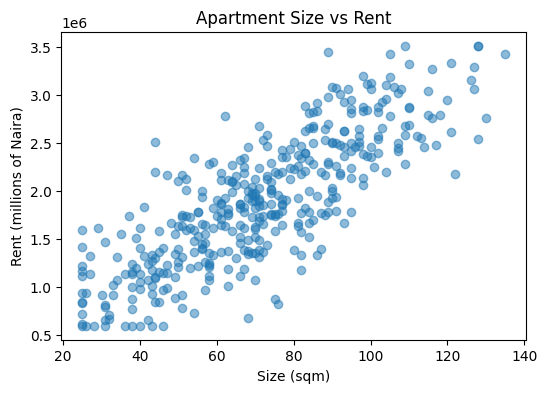

In [40]:
plt.figure(figsize=(6,4))
plt.scatter(df['size_sqm'], df['rent_per_year'], alpha=0.5)
plt.title('Apartment Size vs Rent')
plt.xlabel('Size (sqm)')
plt.ylabel('Rent (millions of Naira)')
plt.show()

**Written answer 1.3:** In 2 or 3 sentences, describe what the chart shows. Is there a pattern? Are the dots exactly on a line? Why or why not?

There seems to be a positive correlation between the size of the building and the amount of rent. This means that generally as the size of the apartment increases, then the amount in rent also increases as well.

---
# Part 2: Prepare the Data

### Task 2.1: Choose features and target
We want to **predict `rent_per_year`**.
1. Which column is the **target (y)**?
2. Which columns will you use as **features (X)**?
3. Which column must you **leave out** because it is only a name tag?
4. Later we will predict `rent_category`. Why must we **not** use `rent_per_year` as a feature for that?

1. The target is the rent_per_year
2. I will use the size of the building, the amount of bedrooms, the distance to the city, whether it has a generator or not and, whether it has security or not.
3. I must leave out apartment_id
4. Because it would give the model the answer directly instead of predicting the rent category

### Task 2.2: Turn words into numbers
`has_generator` and `has_security` contain Yes and No. Make a **copy** of `df` called `df_ml`, then create two new number columns, `has_generator_num` and `has_security_num`, where **Yes becomes 1** and **No becomes 0**. Then make a list called `features` with your five feature columns (use the new number columns), and show the old and new columns side by side to check.

In [41]:
df_ml=df.copy()
df_ml['has_security_num']=df['has_security'].map({'Yes':1,'No':0})
df_ml['has_generator_num']=df['has_generator'].map({'Yes':1,'No':0})
features=['size_sqm','bedrooms','distance_to_city_km','has_generator_num','has_security_num']
df_ml[['has_generator_num','has_generator','has_security','has_security_num']]

,has_generator_num,has_generator,has_security,has_security_num
0,0,No,No,0
1,1,Yes,No,0
2,1,Yes,Yes,1
3,0,No,No,0
4,0,No,Yes,1
...,...,...,...,...
395,0,No,Yes,1
396,0,No,Yes,1
397,0,No,Yes,1
398,1,Yes,Yes,1


### Task 2.3: Split the data
Split `df_ml` into a **training** set (80%) and a **testing** set (20%) using `random_state=42`. Call them `train_df` and `test_df`. Print how many apartments are in each.

In [42]:
train_df, test_df = train_test_split(df_ml, test_size=0.2, random_state=42)
print(len(train_df))
print(len(test_df))

320
80


### Task 2.4: Explain it in your own words
(a) Why did we change Yes and No into 1 and 0?
(b) Why do we keep 20% of the apartments hidden from the model until the end?

1. We changed Yes and No into numbers so that python would be able to calculate the numbers which makes it easeir to make preictions.
2. We kept 20% of the apartments hidden because if the model was able to see it then it wouldnt have to predict anything, which would make the whole model redundant.



---
# Part 3: Regression, Predict the Rent

### Task 3.1: A model with ONE feature
Train a `LinearRegression` model that uses **only `size_sqm`** to predict `rent_per_year`. Predict the rent for the test apartments and print the **MAE** (in naira) and the **R²**.

In [43]:
model_one = LinearRegression()
model_one.fit(train_df[['size_sqm']], train_df['rent_per_year'])
predictions_one = model_one.predict(test_df[['size_sqm']])
mae_one = mean_absolute_error(test_df['rent_per_year'], predictions_one)
r2_one = r2_score(test_df['rent_per_year'], predictions_one)
print(mae_one)
print(r2_one)
results = pd.DataFrame({
    "Actual price": test_df['rent_per_year'].values,
    "Predicted price": predictions_one.round(0)
})
results

307704.1278625683
0.618127159919531


,Actual price,Predicted price
0,2870000,2595364.0
1,1930000,2323457.0
2,2130000,2074209.0
3,1230000,1598373.0
4,2430000,2028892.0
...,...,...
75,1850000,1915597.0
76,2550000,2844611.0
77,1150000,1326466.0
78,1980000,1870279.0


### 🎯 Guess first (before you run anything)
In Task 3.2 you will train a model with **all five features** instead of just size. Will its **MAE be bigger, smaller, or about the same** as the one-feature model? Write your guess and **why** *before* you run the code. Then check it against your result.

It will be smaller because with more features it gives more conditions for the model to be more accurate

### Task 3.2: A model with ALL FIVE features
Now train a second `LinearRegression` model using **all five features** in `features`. Print its **MAE** and **R²**. Then show a small table with each feature and the **slope** the model learned.

In [44]:
model_multi=LinearRegression()
model_multi.fit(train_df[features], train_df['rent_per_year'])
predictions_multi=model_multi.predict(test_df[features])
r2_multi=r2_score(test_df['rent_per_year'],predictions_multi)
mae_multi=mean_absolute_error(test_df['rent_per_year'],predictions_multi)
print(r2_multi)
print(mae_multi)
learned = pd.DataFrame({
    "feature": features,                                      # the six column names
    "slope_learned_by_model": model_multi.coef_.round(2),     # the six slopes, same order, rounded
})
learned

0.8972706081668567
171685.3166188797


,feature,slope_learned_by_model
0,size_sqm,10704.62
1,bedrooms,381717.87
2,distance_to_city_km,-20274.44
3,has_generator_num,318491.28
4,has_security_num,240705.12


### Task 3.3: Actual vs predicted
Draw a chart for the **five-feature model**: put the **real** rent (in millions) across the bottom and the **predicted** rent up the side, with one dot per test apartment. Add a red dashed "perfect guess" line, where predicted equals real.

In [45]:
results = pd.DataFrame({
    "Actual price": test_df['rent_per_year'].values,
    "Predicted price": predictions_multi.round(0)
})
results

,Actual price,Predicted price
0,2870000,2706577.0
1,1930000,2189596.0
2,2130000,1982637.0
3,1230000,906481.0
4,2430000,2313260.0
...,...,...
75,1850000,1375774.0
76,2550000,2709883.0
77,1150000,1236410.0
78,1980000,2056418.0


### Task 3.4: A new apartment
A new apartment has **3 bedrooms**, **90 square metres**, is **10 km** from the city centre, **has a generator** and **has security**. Use your **five-feature model** to predict its yearly rent. Print the answer in naira.

In [46]:
new_apartment=pd.DataFrame({
    'size_sqm':[90],
    'bedrooms':[3],
    'distance_to_city_km':[10],
    'has_generator_num':[1],
    'has_security_num':[1]
})
print(model_multi.predict(new_apartment))

[2730362.44059727]


---
# Part 4: Classification, Expensive or Affordable?

### Task 4.1: Train a Decision Tree
Predict **`rent_category`** using the **same five features**. Train a `DecisionTreeClassifier` with `max_depth=3` and `random_state=42`, predict the test apartments, and print the **accuracy** as a percentage.

In [47]:

model_tree=DecisionTreeClassifier(max_depth=3, random_state=42)
model_tree.fit(train_df[features],train_df['rent_category'])
tree_prediction = model_tree.predict(test_df[features])
print("predictions:", list(tree_prediction[:10]))
print("actual answer:", list(test_df['rent_category'].values[:10]))
accuracy= accuracy_score(test_df['rent_category'], tree_prediction)
print(f"Accuracy: {accuracy:.0%}")

predictions: ['Expensive', 'Expensive', 'Affordable', 'Affordable', 'Expensive', 'Affordable', 'Expensive', 'Expensive', 'Affordable', 'Expensive']
actual answer: ['Expensive', 'Affordable', 'Expensive', 'Affordable', 'Expensive', 'Affordable', 'Expensive', 'Expensive', 'Expensive', 'Expensive']
Accuracy: 78%


### Task 4.2: Look inside the tree
Draw the tree. Then answer in the cell below: **What is the first question the tree asks? Which features does it use?**

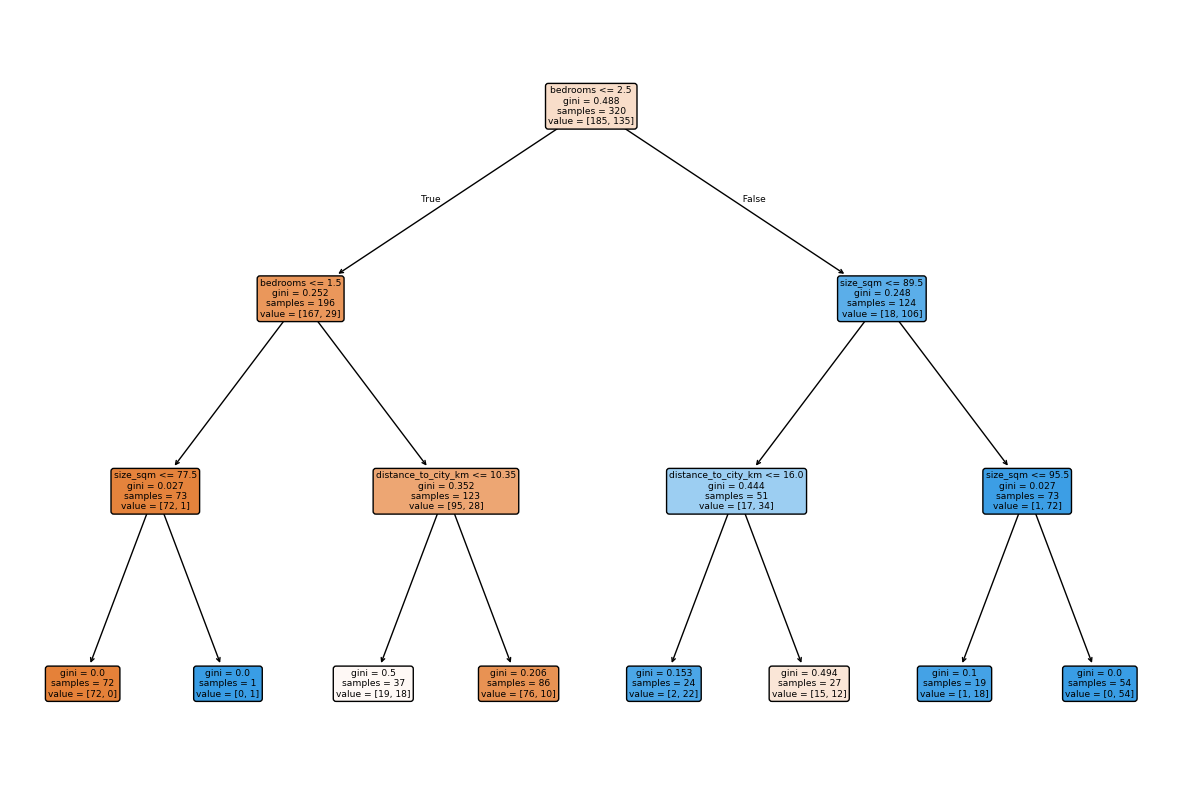

In [48]:
plt.figure(figsize=(15,10))
plot_tree(model_tree, feature_names=features, filled=True, rounded=True);

**Written answer 4.2:** What is the first question the tree asks? Which features does it use?

Are the bedrooms less than 2.5?
it uses the distance to city, the amount of bedrooms and the size to make the model.



### Task 4.3: Classify the new apartment
Ask the **tree** about the same new apartment from Task 3.4. Does it say Expensive or Affordable? Does that match what the rent prediction suggests?

In [49]:
model_tree.predict(new_apartment)

array(['Expensive'], dtype=object)

---
# Part 5: Overfitting

### 🎯 Guess first (before you run anything)
In Task 5.1 you will let the tree ask more and more questions (depth 1 up to 15). As the depth grows, what do you think will happen to the **training accuracy**? And to the **testing accuracy**? Write your guess and why, *then* run the code and compare.

It will become more accurate because it will have more questions to be able to make its guess more accurate.

### Task 5.1: Try 15 different tree depths
Train **15 trees** with `max_depth` from **1 to 15**. For each, record the accuracy on the **training** apartments and on the **testing** apartments. Draw both on one chart, and print the depth with the **best test accuracy**.

Best test accuracy: 90.0% at depth 5


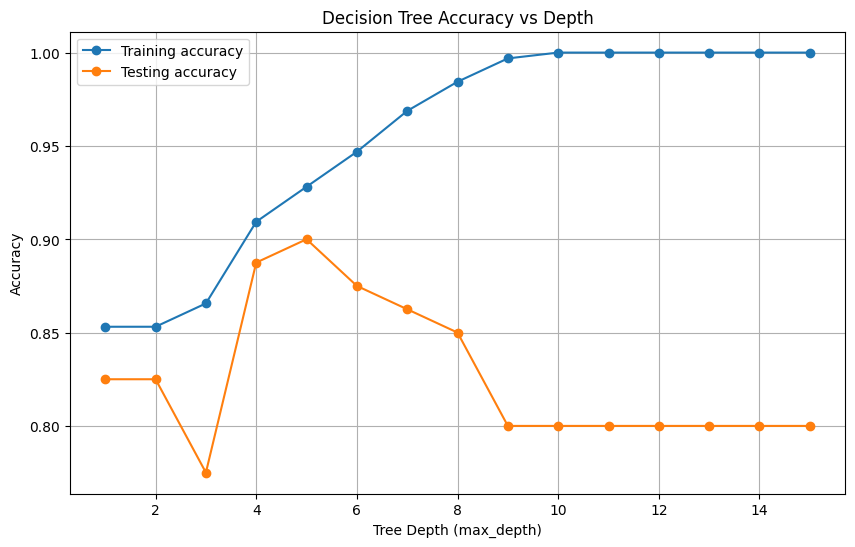

In [50]:
depths = range(1, 16)
train_accuracies = []
test_accuracies = []

for d in depths:
  t = DecisionTreeClassifier(max_depth=d, random_state=42)
  t.fit(train_df[features], train_df['rent_category'])
  train_accuracies.append(t.score(train_df[features], train_df['rent_category']))
  test_accuracies.append(t.score(test_df[features], test_df['rent_category']))

# Find and print the best depth based on testing accuracy
best_accuracy = max(test_accuracies)
best_depth = list(depths)[test_accuracies.index(best_accuracy)]
print(f"Best test accuracy: {best_accuracy:.1%} at depth {best_depth}")

# Draw the chart once after the loop finishes
plt.figure(figsize=(10, 6))
plt.plot(depths, train_accuracies, label='Training accuracy', marker='o')
plt.plot(depths, test_accuracies, label='Testing accuracy', marker='o')
plt.xlabel('Tree Depth (max_depth)')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs Depth')
plt.legend()
plt.grid(True)
plt.show()

### Task 5.2: A tree with no limit
Train one tree with `max_depth=None` (no limit) and print its **training** accuracy and **testing** accuracy.

In [51]:
tree=DecisionTreeClassifier(max_depth=None, random_state=42)
tree.fit(train_df[features], train_df['rent_category'])
Accuracy1=tree.score(train_df[features], train_df['rent_category'])
Accuracy2=tree.score(test_df[features], test_df['rent_category'])
print(Accuracy1)
print(Accuracy2)


1.0
0.8


**Written answer 5:** (a) What do you notice about the two lines in your chart? (b) What is **overfitting**? (c) Which `max_depth` would you choose, and why **not** the biggest one?

a. The training line kept increasing until it reached 100 percent accuracy while the testing line went up and then back down to 80 percent.

b. Overfitting is the model memorises the answers instead of trying to predict the outcome.

c.I will chose a max depth of 4 I wont choose the biggest one because it will cause the model to become overfitted.

---
# Part 6: Reflection

Answer each question in 1 to 3 sentences.

**6.1** Which regression model did better, the one-feature model or the five-feature model? Use the **MAE or R²** numbers as evidence.

**6.2** In your own words, what does the slope for `has_generator_num` mean?

**6.3** Why do we test the model on apartments it has **never seen**?

**6.4** Name **one limit** of this project.

**6.5** Close your class notebooks and answer from your head. (a) What is the difference between an **algorithm** and a **model**? Use this project as your example. (b) In scikit-learn we **create**, **fit** and **predict**. What does each step do?

The five-feature model did it better becuse the MAE for it was smaller and the R2 number was closer to one.

6.2 I think it means how much the has_generator_num feature affects the price of the apartment.

6.3 we show it apartments it has never seen so that it doesnt just state the answers that it already knows.

6.4 The prediction is not exact and there is a gap between the actual value and the predictied one.

6.5 An algorithm is a calculation that is used in a model, an example is the algorithm used in the decision tree model. A model is a program that is used to make predictions using datasets that it has been trained on. and example is the decision tree model.

Create: Creates a model

Fit: adds features to the model so that it can make predictions.

Predict: uses all features that were added to make predictions.

---
# 📤 How to Submit Your Project

When you finish, you will put your project on **GitHub** and send your links on **Slack**. Follow these steps in order.

### Step 1: Check your notebook
1. Click **Runtime → Run all** and wait until it finishes.
2. Scroll through. **No cell should show a red error**, and your charts and answers should all be visible.

### Step 2: Download your notebook
In Colab click **File → Download → Download .ipynb**. Rename it to something clear, like `yourname_abuja_rent_project.ipynb`.

### Step 3: Make a free GitHub account (skip if you have one)
Go to **github.com**, click **Sign up**, and follow the steps. Choose a simple, professional username (it becomes part of your link).

### Step 4: Create a repository (a folder for your project)
1. Log in. Click the **+** at the top right, then **New repository**.
2. **Repository name:** `abuja-rent-ml-project`
3. **Description:** `Machine learning project: predicting apartment rent in Abuja`
4. Choose **Public** (so we can open it).
5. Tick **Add a README file**.
6. Click **Create repository**.

### Step 5: Upload your files
1. On your repository page, click the **Add file** dropdown, then **Upload files**.
2. Drag in **two files**: your notebook (`.ipynb`) and `abuja_apartments_400.csv`. (Or click *choose your files*.)
3. In the "Commit changes" box type a short message, like `Add project notebook and dataset`.
4. Choose **Commit directly to the main branch**, then click **Commit changes**.

### Step 6: Write your README
Your README is the front page of your project. Click `README.md`, then the **pencil icon** (edit). Replace the text with the template below, fill in your own details, and click **Commit changes**.

```
# Abuja Apartment Rent Predictor

My first machine learning project. I used 400 made-up Abuja apartments to
(1) predict the yearly rent and (2) label apartments as Expensive or Affordable.

## What is in this repository
- `yourname_abuja_rent_project.ipynb`: my notebook with all the code, charts and answers
- `abuja_apartments_400.csv`: the dataset

## What I did
- Explored the data and drew charts
- Trained a Linear Regression model to predict rent (MAE: ₦_____, R²: ____)
- Trained a Decision Tree to classify apartments (accuracy: ____%)
- Compared different tree depths to understand overfitting

## What I learned (in my own words)
- ...
- ...
- ...

## Tools
Python, pandas, matplotlib, scikit-learn, Google Colab

## Author
Your Name
```

### Step 7: Check your work
Refresh your repository page. Click your notebook. It should open and **show your charts and results**. If you see "Unable to render", download it again from Colab after running all cells and re-upload it.

### Step 8: Get your two links
1. **GitHub link:** copy the address of your repository page from the address bar. It looks like `https://github.com/your-username/abuja-rent-ml-project`.
2. **Colab link:** in Colab click **Share** (top right), under *General access* choose **Anyone with the link**, set it to **Viewer**, then click **Copy link**.

> 💡 You can also use **File → Save a copy in GitHub** inside Colab. It only copies the notebook and **not the CSV**, so you would still need to upload the CSV in Step 5.

### Step 9: Submit on Slack
Post your links on the slack using this format:

```
Name: Your Full Name
GitHub: https://github.com/your-username/abuja-rent-ml-project

```

✅ **Before you post, check:** the repo is **Public**, both links open when you click them, and the notebook on GitHub shows your charts.